<a href="https://colab.research.google.com/github/jerrygh2018/pytorch_training/blob/main/pytorch_essentials_app_first.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install transformers datasets

In [ ]:
!wget https://raw.githubusercontent.com/lftraining/LFD273-code/main/data/100KUsedCar/car_prices.zip
!unzip car_prices.zip -d car_prices

--2026-10-21 11:39:09--  https://raw.githubusercontent.com/lftraining/LFD273-code/main/data/100KUsedCar/car_prices.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1152744 (1.1M) [application/zip]
Saving to: ‘car_prices.zip’

car_prices.zip      100%[===================>]   1.10M  --.-KB/s    in 0.05s   

2026-10-21 11:39:10 (22.3 MB/s) - ‘car_prices.zip’ saved [1152744/1152744]

Archive:  car_prices.zip
  inflating: car_prices/audi.csv     
  inflating: car_prices/bmw.csv      
  inflating: car_prices/cclass.csv   
  inflating: car_prices/focus.csv    
  inflating: car_prices/ford.csv     
  inflating: car_prices/hyundi.csv   
  inflating: car_prices/merc.csv     
  inflating: car_prices/skoda.csv    
  inflating: car_prices/toyota.csv   
  inflating: ca

# Get Dataset

In [ ]:
import os

def filter_for_data(filename):
         return ("unclean" not in filename) and ("focus" not in filename) and ("cclass" not in filename) and filename.endswith(".csv")

folder = './car_prices'
data_files = sorted([os.path.join(folder, fname)
                     for fname in os.listdir(folder)
                     if filter_for_data(fname)])
data_files

['./car_prices/audi.csv',
 './car_prices/bmw.csv',
 './car_prices/ford.csv',
 './car_prices/hyundi.csv',
 './car_prices/merc.csv',
 './car_prices/skoda.csv',
 './car_prices/toyota.csv',
 './car_prices/vauxhall.csv',
 './car_prices/vw.csv']

In [ ]:
from datasets import load_dataset, Split

colnames = ['model', 'year', 'price', 'transmission', 'mileage', 'fuel_type', 'road_tax', 'mpg', 'engine_size', 'manufacturer']

dataset = load_dataset(path="csv",
                        data_files=data_files,
                        sep=',',
                        skiprows=1,
                        column_names=colnames,
                        split=Split.ALL)
dataset.features, dataset.num_columns, dataset.shape

Generating train split: 0 examples [00:00, ? examples/s]

({'model': Value('string'),
  'year': Value('int64'),
  'price': Value('int64'),
  'transmission': Value('string'),
  'mileage': Value('int64'),
  'fuel_type': Value('string'),
  'road_tax': Value('int64'),
  'mpg': Value('float64'),
  'engine_size': Value('float64'),
  'manufacturer': Value('float64')},
 10,
 (99187, 10))

In [ ]:
import numpy as np

# Calculate Q1 and Q3 for the 'price' column
prices = np.array(dataset['price'])
Q1 = np.percentile(prices, 25)
Q3 = np.percentile(prices, 75)

# Calculate IQR
IQR = Q3 - Q1

# Define outlier bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter out extreme data
dataset = dataset.filter(lambda example: example['price'] >= lower_bound and example['price'] <= upper_bound)

print(f"Original dataset size: {len(prices)}")
print(f"Filtered dataset size: {len(dataset)}")

Filter:   0%|          | 0/99187 [00:00<?, ? examples/s]

Original dataset size: 99187
Filtered dataset size: 95518


In [ ]:
train_test = dataset.train_test_split(train_size=0.8)
val_test = train_test['test'].train_test_split(train_size=0.5)
from datasets import DatasetDict
datasets = DatasetDict({'train': train_test['train'], # training set from first split
                        'val': val_test['train'],     # test set from first split, split further and renamed
                        'test': val_test['test']})    # test set from first split, split further datasets

In [ ]:
datasets

DatasetDict({
    train: Dataset({
        features: ['model', 'year', 'price', 'transmission', 'mileage', 'fuel_type', 'road_tax', 'mpg', 'engine_size', 'manufacturer'],
        num_rows: 79349
    })
    val: Dataset({
        features: ['model', 'year', 'price', 'transmission', 'mileage', 'fuel_type', 'road_tax', 'mpg', 'engine_size', 'manufacturer'],
        num_rows: 9919
    })
    test: Dataset({
        features: ['model', 'year', 'price', 'transmission', 'mileage', 'fuel_type', 'road_tax', 'mpg', 'engine_size', 'manufacturer'],
        num_rows: 9919
    })
})

In [ ]:
cont_attr = ['year', 'mileage', 'road_tax', 'mpg', 'engine_size']
cat_attr = ['model', 'transmission', 'fuel_type']
def gen_encoder_dict(col):
    values = sorted(dataset.unique(col))
    values += ['UNKNOWN']
    return dict(zip(values, range(len(values))))

dropdown_encoders = {col: gen_encoder_dict(col) for col in cat_attr}

Flattening the indices:   0%|          | 0/95518 [00:00<?, ? examples/s]

In [ ]:
dropdown_encoders['fuel_type']

{'Diesel': 0,
 'Electric': 1,
 'Hybrid': 2,
 'Other': 3,
 'Petrol': 4,
 'UNKNOWN': 5}

In [ ]:
datasets['train'][0]

{'model': ' Focus',
 'year': 2018,
 'price': 12700,
 'transmission': 'Manual',
 'mileage': 14363,
 'fuel_type': 'Petrol',
 'road_tax': 145,
 'mpg': 60.1,
 'engine_size': 1.0,
 'manufacturer': None}

In [ ]:
from datasets import Dataset
dummy = Dataset.from_dict({'seq': list(range(10))})
double_dummy = dummy.map(lambda row: {'double': row['seq'] * 2})
list_dummy = dummy.map(lambda row: {'seq': [row['seq'], row['seq'] * 2]})
list_dummy[:]

Map:   0%|          | 0/10 [00:00<?, ? examples/s]

Map:   0%|          | 0/10 [00:00<?, ? examples/s]

{'seq': [[0, 0],
  [1, 2],
  [2, 4],
  [3, 6],
  [4, 8],
  [5, 10],
  [6, 12],
  [7, 14],
  [8, 16],
  [9, 18]]}

In [ ]:
double_dummy[:]

{'seq': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 'double': [0, 2, 4, 6, 8, 10, 12, 14, 16, 18]}

In [ ]:
dummy[:]

{'seq': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]}

In [ ]:
import numpy as np

def preproc(row):
    colnames = ['model', 'year', 'price', 'transmission', 'mileage', 'fuel_type', 'road_tax', 'mpg', 'engine_size']

    cat_attr = ['model', 'transmission', 'fuel_type']
    cont_attr = ['year', 'mileage', 'road_tax', 'mpg', 'engine_size']
    target = 'price'


    cont_X = [float(row[name]) for name in cont_attr]
    cat_X = [dropdown_encoders[name].get(row[name], dropdown_encoders[name]['UNKNOWN']) for name in cat_attr]

    return {'label': np.array([float(row[target])], dtype=np.float32),
            'cont_X': np.array(cont_X, dtype=np.float32),
            'cat_X': np.array(cat_X, dtype=int)}

datasets = datasets.map(preproc)
datasets

Map:   0%|          | 0/76414 [00:00<?, ? examples/s]

Map:   0%|          | 0/9552 [00:00<?, ? examples/s]

Map:   0%|          | 0/9552 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['model', 'year', 'price', 'transmission', 'mileage', 'fuel_type', 'road_tax', 'mpg', 'engine_size', 'manufacturer', 'label', 'cont_X', 'cat_X'],
        num_rows: 76414
    })
    val: Dataset({
        features: ['model', 'year', 'price', 'transmission', 'mileage', 'fuel_type', 'road_tax', 'mpg', 'engine_size', 'manufacturer', 'label', 'cont_X', 'cat_X'],
        num_rows: 9552
    })
    test: Dataset({
        features: ['model', 'year', 'price', 'transmission', 'mileage', 'fuel_type', 'road_tax', 'mpg', 'engine_size', 'manufacturer', 'label', 'cont_X', 'cat_X'],
        num_rows: 9552
    })
})

In [ ]:
datasets = datasets.select_columns(['label', 'cont_X', 'cat_X'])
datasets

DatasetDict({
    train: Dataset({
        features: ['label', 'cont_X', 'cat_X'],
        num_rows: 76414
    })
    val: Dataset({
        features: ['label', 'cont_X', 'cat_X'],
        num_rows: 9552
    })
    test: Dataset({
        features: ['label', 'cont_X', 'cat_X'],
        num_rows: 9552
    })
})

In [ ]:
datasets['train'][:2]

{'label': [[12700.0], [11000.0]],
 'cont_X': [[2018.0, 14363.0, 145.0, 60.099998474121094, 1.0],
  [2018.0, 22140.0, 145.0, 56.5, 1.0]],
 'cat_X': [[61, 1, 4], [60, 1, 4]]}

In [ ]:
datasets = datasets.with_format('torch')
datasets['train'][:2]

{'label': tensor([[26490.],
         [10069.]]),
 'cont_X': tensor([[2.0160e+03, 3.2494e+04, 2.0000e+02, 4.5600e+01, 2.2000e+00],
         [2.0170e+03, 1.7613e+04, 1.4500e+02, 6.2800e+01, 1.0000e+00]]),
 'cat_X': tensor([[161,   3,   0],
         [ 58,   1,   4]])}

In [ ]:
datasets['train'].__getitem__(1)

{'label': tensor([15698.]),
 'cont_X': tensor([2.0190e+03, 7.5810e+03, 1.4500e+02, 5.6500e+01, 1.5000e+00]),
 'cat_X': tensor([79,  1,  0])}

In [ ]:
from torch.utils.data import DataLoader

dataloaders = {}

dataloaders['train'] = DataLoader(dataset=datasets['train'], batch_size=128, drop_last=True, shuffle=True)
dataloaders['val'] = DataLoader(dataset=datasets['val'], batch_size=128)
dataloaders['test'] = DataLoader(dataset=datasets['test'], batch_size=128)

In [ ]:
next(iter(dataloaders['train']))

{'label': tensor([[16370.],
         [16990.],
         [20999.],
         [19491.],
         [ 9490.],
         [31980.],
         [16690.],
         [19975.],
         [10500.],
         [ 5699.],
         [ 7999.],
         [19346.],
         [31499.],
         [16290.],
         [ 4995.],
         [ 8995.],
         [37980.],
         [36500.],
         [11000.],
         [28160.],
         [10000.],
         [ 9900.],
         [28995.],
         [ 2991.],
         [17982.],
         [10799.],
         [11999.],
         [13700.],
         [ 4990.],
         [18490.],
         [30298.],
         [12250.],
         [37995.],
         [12795.],
         [ 1954.],
         [11499.],
         [13300.],
         [11498.],
         [16950.],
         [17000.],
         [ 8995.],
         [26995.],
         [17900.],
         [13998.],
         [18498.],
         [15200.],
         [14990.],
         [12500.],
         [ 8998.],
         [11500.],
         [11995.],
         [18499.],
   

In [ ]:
import torch.nn as nn

batch = next(iter(dataloaders['train']))
batch['cont_X'].mean(axis=0), batch['cont_X'].std(axis=0, unbiased=False)

(tensor([2.0170e+03, 2.2345e+04, 1.2051e+02, 5.5342e+01, 1.6734e+00]),
 tensor([2.1540e+00, 2.0423e+04, 6.4617e+01, 1.5767e+01, 5.4105e-01]))

In [ ]:
bn_layer = nn.BatchNorm1d(num_features=len(cont_attr))

normalized_cont = bn_layer(batch['cont_X'])
normalized_cont.mean(axis=0), normalized_cont.std(axis=0, unbiased=False)

(tensor([-2.9758e-05,  3.7253e-08, -4.4703e-08,  3.3528e-08, -3.7625e-07],
        grad_fn=<MeanBackward1>),
 tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000], grad_fn=<StdBackward0>))

In [ ]:
bn_layer.state_dict()

OrderedDict([('weight', tensor([1., 1., 1., 1., 1.])),
             ('bias', tensor([0., 0., 0., 0., 0.])),
             ('running_mean',
              tensor([2.0170e+02, 2.2345e+03, 1.2051e+01, 5.5342e+00, 1.6734e-01])),
             ('running_var',
              tensor([1.3676e+00, 4.2036e+07, 4.2172e+02, 2.5957e+01, 9.2950e-01])),
             ('num_batches_tracked', tensor(1))])

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

class FFN(nn.Module):
    def __init__(self, n_cont, cat_list, emb_dim):
        super().__init__()
        # Embedding layers
        embedding_layers = []
        # Creates one embedding layer for each categorical feature
        for vocab_size in cat_list:
            embedding_layers.append(nn.Embedding(vocab_size, emb_dim))
        self.emb_layers = nn.ModuleList(embedding_layers)

        # Total number of embedding dimensions
        self.n_emb = len(cat_list) * emb_dim
        self.n_cont = n_cont

        # Batch Normalization layer for continuous features
        self.bn_input = nn.BatchNorm1d(n_cont)

        # Linear Layer(s)
        lin_layers = []
        # The input layers takes as many inputs as the number of continuous features
        # plus the total number of concatenated embeddings
        input_dim = self.n_emb + self.n_cont
        hidden_dim_1 = 512  # Example hidden layer size
        hidden_dim_2 = 256  # Example hidden layer size

        lin_layers.append(nn.Linear(input_dim, hidden_dim_1, bias=True))
        lin_layers.append(nn.Linear(hidden_dim_1, hidden_dim_2, bias=True))
        self.lin_layers = nn.ModuleList(lin_layers)

        # Batch Normalization Layer(s)
        bn_layers = []
        # Creates batch normalization layers for each linear hidden layer
        bn_layers.append(nn.BatchNorm1d(hidden_dim_1))
        bn_layers.append(nn.BatchNorm1d(hidden_dim_2))
        self.bn_layers = nn.ModuleList(bn_layers)

        # The output layer must have as many inputs as there were outputs in the last hidden layer
        self.output_layer = nn.Linear(hidden_dim_2, 1, bias=True)

        # Layer initialization
        for lin_layer in self.lin_layers:
            nn.init.kaiming_normal_(lin_layer.weight.data, nonlinearity='relu')
            if lin_layer.bias is not None:
                nn.init.zeros_(lin_layer.bias.data)
        nn.init.kaiming_normal_(self.output_layer.weight.data, nonlinearity='relu')
        if self.output_layer.bias is not None:
            nn.init.zeros_(self.output_layer.bias.data)

    def forward(self, inputs):
        # The inputs are the features as returned in the first element of a tuple
        # coming from the dataset/dataloader
        cont_data, cat_data = inputs

        embeddings = []
        # Retrieve embeddings for each categorical attribute and concatenate them
        for i, emb_layer in enumerate(self.emb_layers):
            embeddings.append(emb_layer(cat_data[:, i]))
        x_cat = torch.cat(embeddings, 1)

        # Normalizes continuous features using Batch Normalization layer
        normalized_cont_data = self.bn_input(cont_data)

        # Concatenate all features together, normalized continuous and embeddings
        x = torch.cat([normalized_cont_data, x_cat], 1)

        # Run the inputs through each layer and applies an activation function and batch norm to each output
        for layer, bn_layer in zip(self.lin_layers, self.bn_layers):
            x = layer(x)
            x = F.relu(x)
            x = bn_layer(x)

        # Run the output of the last linear layer through the output layer
        x = self.output_layer(x)
        return x

In [ ]:
n_cont = len(cont_attr)
cat_list = [np.array(list(dropdown_encoders[name].values())) for name in cat_attr]
n_cont, cat_list

(5,
 [array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
          13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
          26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
          39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
          52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
          65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
          78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
          91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
         104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
         117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
         130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
         143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
         156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
         169, 170, 171, 172, 173, 

In [ ]:
torch.manual_seed(42)

# write your code here
emb_dim = 10
model = FFN(n_cont, [len(o) for o in cat_list], emb_dim)

In [ ]:
loss_fn = nn.MSELoss()

optimizer = optim.Adam(params=model.parameters(), lr = 3e-3)

In [ ]:
from tqdm import tqdm

device = 'cuda' if torch.cuda.is_available() else 'cpu'

n_epochs = 20
losses = torch.empty(n_epochs)
val_losses = torch.empty(n_epochs)

best_loss = torch.inf
best_epoch = -1
patience = 3

model.to(device)

progress_bar = tqdm(range(n_epochs))


for epoch in progress_bar:
    batch_losses = []

    ## Training

    for i, batch in enumerate(dataloaders['train']):
        model.train()
        # Send batch features and targets to the device
        X_cont = batch['cont_X'].to(device)
        X_cat = batch['cat_X'].to(device)
        y = batch['label'].to(device)

        # Step 1- forward Pass
        predictions = model((X_cont, X_cat))

        # Step 2- computing the loss
        loss = loss_fn(predictions, y)

        # Step 3- computing the gradients
        loss.backward()

        # Step 4- updating parameters and zeroing gradients
        optimizer.step()
        optimizer.zero_grad()

        batch_losses.append(loss.item())

    losses[epoch] = torch.tensor(batch_losses).mean()

    ## Validation
    with torch.inference_mode():
        batch_losses = []
        model.eval()
        for i, val_batch in enumerate(dataloaders['val']):
            # Send batch features and targets to the device
            X_cont = val_batch['cont_X'].to(device)
            X_cat = val_batch['cat_X'].to(device)
            y = val_batch['label'].to(device)

            # Step 1- forward pass
            predictions = model((X_cont, X_cat))

            # Step 2- computing the loss
            loss = loss_fn(predictions, y)
            batch_losses.append(loss.item())

        val_losses[epoch] = torch.tensor(batch_losses).mean()

    if val_losses[epoch] < best_loss:
        best_loss = val_losses[epoch]
        best_epoch = epoch
        torch.save({
            'model': model.state_dict(),
            'optimizer': optimizer.state_dict()},
            "best_model.pth")
    elif (epoch - best_epoch) > patience:
        print(f"Early stopping at epoch #{epoch}")
        break

 55%|█████▌    | 11/20 [01:49<01:29,  9.98s/it]

Early stopping at epoch #11


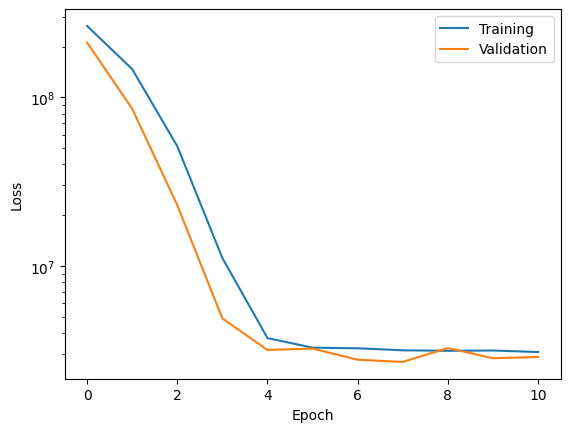

In [ ]:
import matplotlib.pyplot as plt

plt.plot(losses[:epoch], label='Training')
plt.plot(val_losses[:epoch], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.yscale('log')
plt.legend()

Text(0.5, 1.0, 'Price')

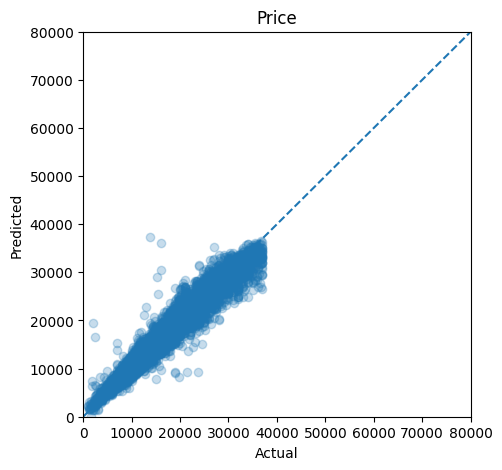

In [ ]:
split = 'val'
y_hat = []
y_true = []
for batch in dataloaders[split]:
    model.eval()
    X_cont = batch['cont_X'].to(device)
    X_cat = batch['cat_X'].to(device)
    y = batch['label'].to(device)
    y_hat.extend(model((X_cont, X_cat)).tolist())
    y_true.extend(y.tolist())

fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.scatter(y_true, y_hat, alpha=0.25)
ax.plot([0, 80000], [0, 80000], linestyle='--')
ax.set_xlabel('Actual')
ax.set_xlim([0, 80000])
ax.set_ylabel('Predicted')
ax.set_ylim([0, 80000])
ax.set_title('Price')

In [ ]:
from sklearn.metrics import r2_score
r2_score(y_true, y_hat)

0.9454870917378196

# New Section